In [1]:
# Experiment 05 — Quantum Fourier Transform and Inverse QFT

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, state_fidelity
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np

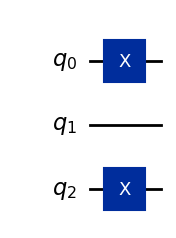

Initial State: {np.str_('101'): np.float64(1.0)}


In [3]:
# Create a three-qubit circuit
qc = QuantumCircuit(3)

# Prepare the |101> state
qc.x(0)
qc.x(2)

# Display the circuit
display(qc.draw("mpl"))

# Check the initial state
initial_state = Statevector.from_instruction(qc)

print("Initial State:", initial_state.probabilities_dict())

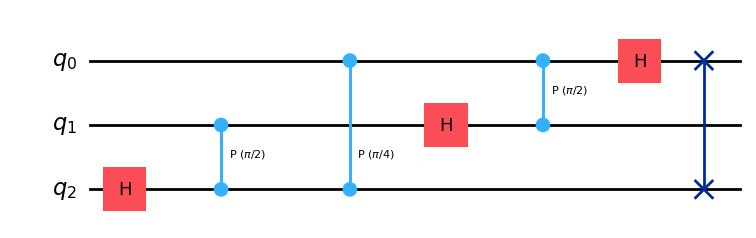

In [4]:
# Create a three-qubit QFT circuit
qft = QuantumCircuit(3)

# Apply Hadamard and controlled-phase gates
qft.h(2)
qft.cp(np.pi / 2, 1, 2)
qft.cp(np.pi / 4, 0, 2)

qft.h(1)
qft.cp(np.pi / 2, 0, 1)

qft.h(0)

# Reverse the qubit order
qft.swap(0, 2)

# Display the QFT circuit
display(qft.draw("mpl"))

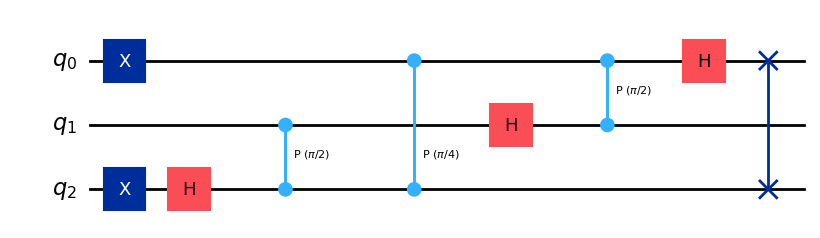

QFT Statevector:
[ 0.3536+0.j     -0.25  -0.25j    0.    +0.3536j  0.25  -0.25j
 -0.3536+0.j      0.25  +0.25j   -0.    -0.3536j -0.25  +0.25j  ]

QFT Probabilities:
{'000': 0.125, '001': 0.125, '010': 0.125, '011': 0.125, '100': 0.125, '101': 0.125, '110': 0.125, '111': 0.125}


In [5]:
# Apply QFT to the prepared state
qc_qft = qc.compose(qft)

# Display the complete circuit
display(qc_qft.draw("mpl"))

# Calculate the transformed state
qft_state = Statevector.from_instruction(qc_qft)

print("QFT Statevector:")
print(np.round(qft_state.data, 4))

print("\nQFT Probabilities:")
print({
    str(k): round(float(v), 4)
    for k, v in qft_state.probabilities_dict().items()
})

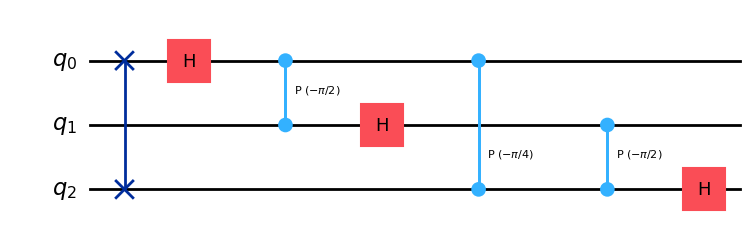

In [6]:
# Create the inverse QFT circuit
inverse_qft = qft.inverse()

# Display the inverse circuit
display(inverse_qft.draw("mpl"))

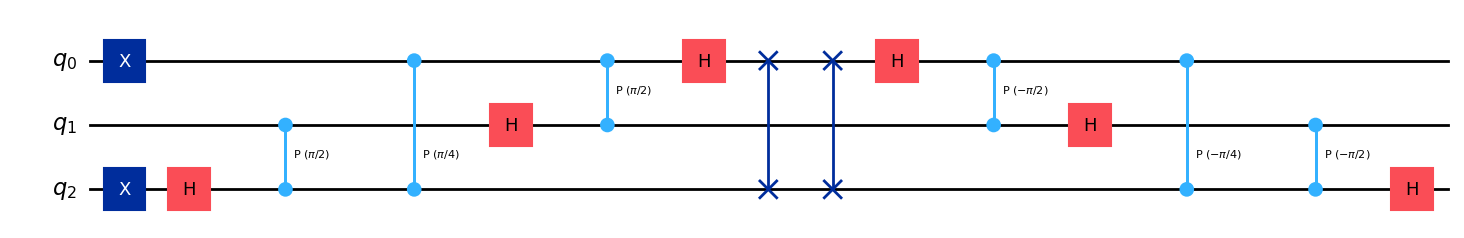

Recovered Statevector:
[ 0.-0.j -0.+0.j  0.+0.j  0.+0.j  0.+0.j  1.+0.j  0.-0.j  0.-0.j]

Recovered Probabilities:
{'000': 0.0, '001': 0.0, '010': 0.0, '011': 0.0, '100': 0.0, '101': 1.0, '110': 0.0, '111': 0.0}


In [7]:
# Apply inverse QFT after QFT
qc_final = qc_qft.compose(inverse_qft)

# Display the complete circuit
display(qc_final.draw("mpl"))

# Calculate the recovered state
final_state = Statevector.from_instruction(qc_final)

print("Recovered Statevector:")
print(np.round(final_state.data, 4))

print("\nRecovered Probabilities:")
print({
    str(k): round(float(v), 4)
    for k, v in final_state.probabilities_dict().items()
})

In [8]:
# Compare the original and recovered states
fidelity = state_fidelity(initial_state, final_state)

print("Original State:", initial_state.probabilities_dict())
print("Recovered State:", final_state.probabilities_dict())

print("State Fidelity:", round(float(fidelity), 6))

Original State: {np.str_('101'): np.float64(1.0)}
Recovered State: {np.str_('000'): np.float64(1.2864597346500117e-34), np.str_('001'): np.float64(3.0127828572915108e-33), np.str_('010'): np.float64(1.2864597346500117e-34), np.str_('011'): np.float64(2.2774456875822723e-35), np.str_('100'): np.float64(1.3580072021223056e-34), np.str_('101'): np.float64(0.9999999999999991), np.str_('110'): np.float64(1.3580072021223056e-34), np.str_('111'): np.float64(2.2774456875822723e-35)}
State Fidelity: 1.0


Measurement Counts: {'101': 1024}


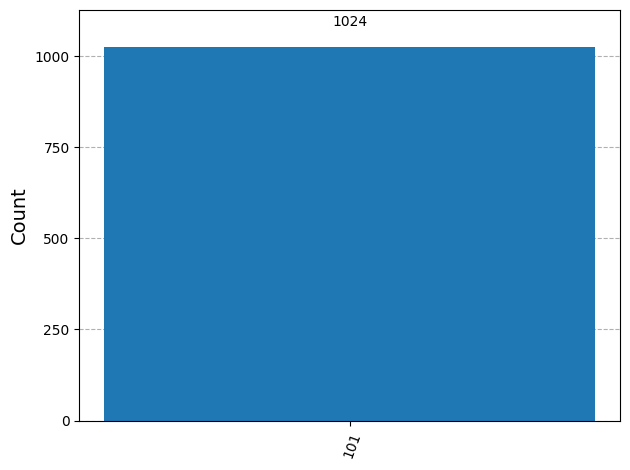

In [9]:
# Add measurements to the final circuit
qc_measure = qc_final.copy()
qc_measure.measure_all()

# Run the circuit 1024 times
simulator = AerSimulator()

result = simulator.run(
    transpile(qc_measure, simulator),
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Measurement Counts:", counts)

# Display the histogram
display(plot_histogram(counts))